# Assignment 2 - Feedforward NN (MNIST)
**Offline version** - runs without internet.
Needs `mnist.npz` in the same folder (see `00_download_once.ipynb`).

In [7]:
%pip install matplotlib scikit-learn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 3.8 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.5 MB 4.3 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.5 MB 4.6 MB/s eta 0:00:02
   ---------------------- ----------------- 5.2/9.5 MB 5.3 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 5.9 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 6.2 MB/s  0:00:01
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.4 MB 8.7 MB/s eta 0:00:01
   ----------------- ---------------------- 3.7/8.4 MB 9.2 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.4 MB 8.8 MB/s eta 0:00:01
   --------------------------

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report

import os

tf.random.set_seed(42)
np.random.seed(42)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.22.0-rc0


In [10]:
def load_mnist(path="mnist.npz"):
    for p in (path, os.path.expanduser("~/.keras/datasets/mnist.npz")):
        if os.path.exists(p):
            with np.load(p, allow_pickle=True) as f:
                return (f["x_train"], f["y_train"]), (f["x_test"], f["y_test"])

    raise FileNotFoundError(
        "mnist.npz not found. Put it in the same folder as this notebook."
    )

(x_train, y_train), (x_test, y_test) = load_mnist()

print("MNIST Dataset Loaded Successfully!")
print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)
print("Testing Images:", x_test.shape)
print("Testing Labels:", y_test.shape)

MNIST Dataset Loaded Successfully!
Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [11]:
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Data preprocessing completed!")

Training data: (60000, 784)
Testing data: (10000, 784)
Data preprocessing completed!


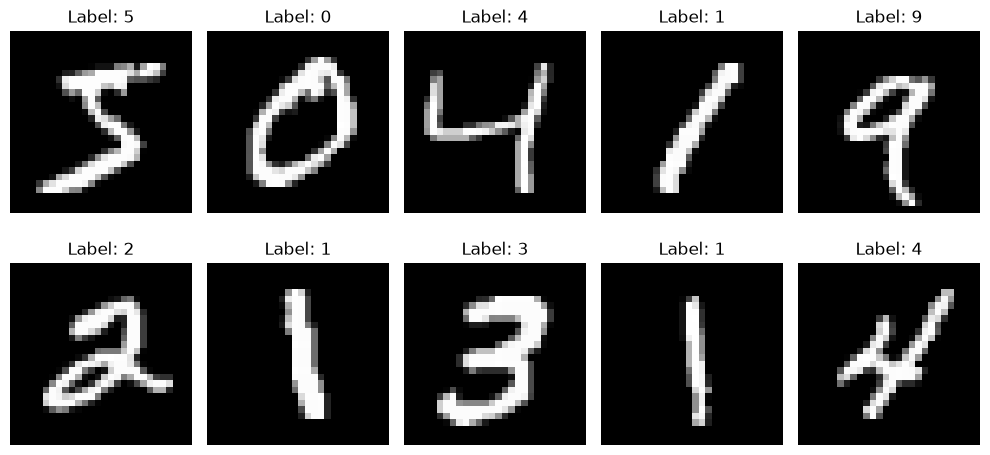

In [12]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation="sigmoid"),
    layers.Dense(128, activation="sigmoid"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [25]:
H = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=50,
    batch_size=128,
    verbose=2
)

Epoch 1/50
469/469 - 2s - 4ms/step - accuracy: 0.9509 - loss: 0.1712 - val_accuracy: 0.9478 - val_loss: 0.1763
Epoch 2/50
469/469 - 2s - 4ms/step - accuracy: 0.9510 - loss: 0.1708 - val_accuracy: 0.9480 - val_loss: 0.1759
Epoch 3/50
469/469 - 2s - 4ms/step - accuracy: 0.9511 - loss: 0.1703 - val_accuracy: 0.9480 - val_loss: 0.1754
Epoch 4/50
469/469 - 2s - 4ms/step - accuracy: 0.9512 - loss: 0.1698 - val_accuracy: 0.9481 - val_loss: 0.1750
Epoch 5/50
469/469 - 2s - 4ms/step - accuracy: 0.9513 - loss: 0.1693 - val_accuracy: 0.9483 - val_loss: 0.1746
Epoch 6/50
469/469 - 2s - 4ms/step - accuracy: 0.9513 - loss: 0.1688 - val_accuracy: 0.9483 - val_loss: 0.1741
Epoch 7/50
469/469 - 2s - 4ms/step - accuracy: 0.9513 - loss: 0.1684 - val_accuracy: 0.9482 - val_loss: 0.1737
Epoch 8/50
469/469 - 2s - 4ms/step - accuracy: 0.9515 - loss: 0.1679 - val_accuracy: 0.9483 - val_loss: 0.1733
Epoch 9/50
469/469 - 2s - 4ms/step - accuracy: 0.9516 - loss: 0.1674 - val_accuracy: 0.9484 - val_loss: 0.1729
E

In [18]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(acc, 4))
print("Test Accuracy Percentage:", round(acc * 100, 2), "%")

Test Loss: 0.2305
Test Accuracy: 0.9335
Test Accuracy Percentage: 93.35 %


In [19]:
pred = model.predict(x_test, verbose=0).argmax(axis=1)

print(classification_report(y_test, pred, digits=4))

              precision    recall  f1-score   support

           0     0.9488    0.9827    0.9654       980
           1     0.9711    0.9762    0.9736      1135
           2     0.9339    0.9176    0.9257      1032
           3     0.9147    0.9238    0.9192      1010
           4     0.9359    0.9369    0.9364       982
           5     0.9130    0.8823    0.8974       892
           6     0.9429    0.9489    0.9459       958
           7     0.9418    0.9280    0.9348      1028
           8     0.9048    0.9076    0.9062       974
           9     0.9199    0.9217    0.9208      1009

    accuracy                         0.9335     10000
   macro avg     0.9327    0.9326    0.9325     10000
weighted avg     0.9334    0.9335    0.9334     10000



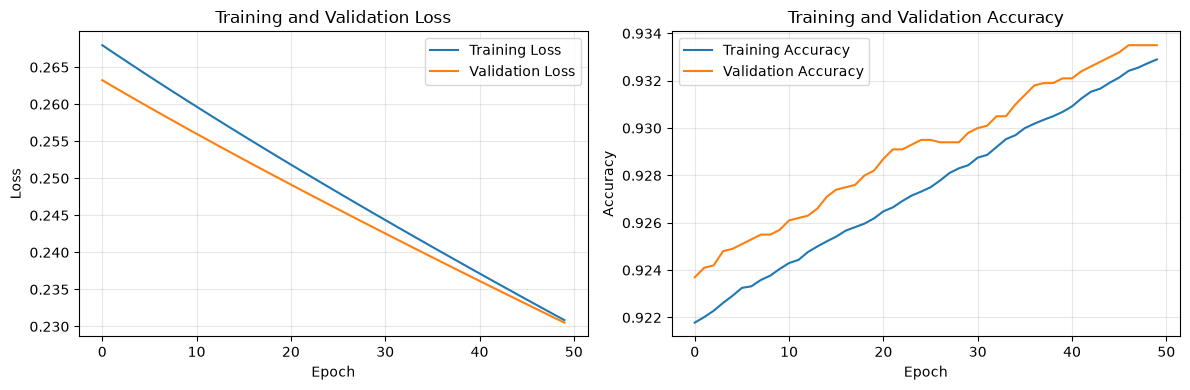

In [20]:
plt.style.use("default")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Loss graph
ax[0].plot(H.history["loss"], label="Training Loss")
ax[0].plot(H.history["val_loss"], label="Validation Loss")
ax[0].set_title("Training and Validation Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Accuracy graph
ax[1].plot(H.history["accuracy"], label="Training Accuracy")
ax[1].plot(H.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("Training and Validation Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("a2_curves.png", dpi=130)
plt.show()

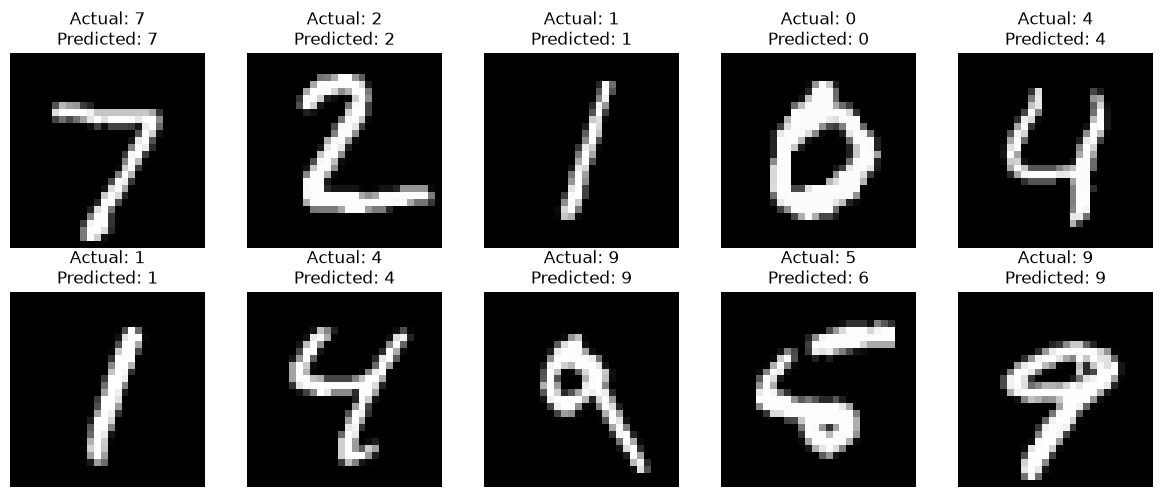

In [21]:
predictions = model.predict(x_test[:10], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
model.save("mnist_feedforward_model.keras")

print("Model saved successfully!")

Model saved successfully!
